# 06 - Model Evaluation & Explainability

## Model selection




In [2]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
import pandas as pd, numpy as np, pickle
from src.evaluation import build_comparison_table

import json

with open("../data/processed/baseline_metrics.json") as f:
    results = json.load(f)

with open("../data/processed/xgboost_metrics.json") as f:
    results.update(json.load(f))

results
table = build_comparison_table(results)
table

,MAE,RMSE,MAPE_%,WAPE_%
Naive (lag_1),119.589,152.944,361.918,87.606
Moving Average (7d),93.319,115.519,347.682,68.361
SARIMA (classical),88.743,108.756,337.820,65.044
XGBoost (gradient boosted trees),69.018,88.161,246.468,50.560


In [3]:
from sklearn.inspection import permutation_importance
from src.utils import FEATURES_DATA_PATH, TARGET_COL, set_seed
from src.forecasting import chronological_split, _encode_categoricals, get_model_feature_cols

set_seed()
df = pd.read_csv(FEATURES_DATA_PATH, parse_dates=['date'])
train, val, test, meta = chronological_split(df)
train_enc, val_enc, test_enc = _encode_categoricals(train, val, test)
feat_cols = get_model_feature_cols()
X_test, y_test = test_enc[feat_cols], test_enc[TARGET_COL]

with open('../models/demand_forecast_model.pkl','rb') as f:
    model = pickle.load(f)

X_sub = X_test.sample(2000, random_state=42)
y_sub = y_test.loc[X_sub.index]
r = permutation_importance(model, X_sub, y_sub, n_repeats=5, random_state=42,
                            scoring='neg_mean_absolute_error', n_jobs=1)
importance = pd.Series(r.importances_mean, index=feat_cols).sort_values(ascending=False)
importance.head(15)

inventory_level            31.518964
lag_28                      0.039966
cat_expanding_mean          0.038657
rolling_mean_28             0.034502
day_of_week                 0.033595
weather_enc                 0.030232
price_vs_competitor_pct     0.026962
price_vs_competitor         0.025229
lag_14                      0.023187
rolling_std_7               0.021614
category_enc                0.021053
lag_7                       0.011470
promotion                   0.005658
week_of_year                0.005469
month                       0.005022
dtype: float64

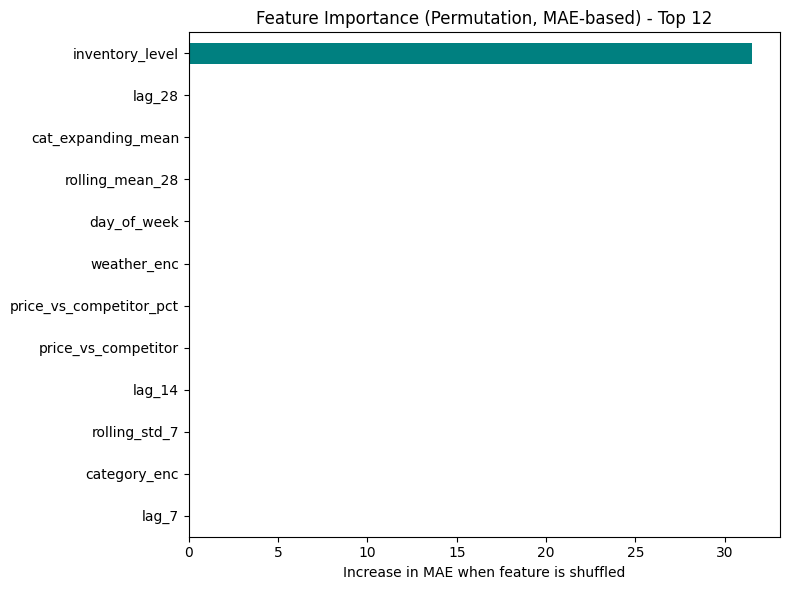

In [4]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,6))
importance.head(12).sort_values().plot(kind='barh', color='teal')
plt.title('Feature Importance (Permutation, MAE-based) - Top 12')
plt.xlabel('Increase in MAE when feature is shuffled')
plt.tight_layout()
plt.savefig('figures/feature_importance.png', dpi=110)
plt.show()

## Save final comparison table for the README / dashboard

In [5]:
table.to_csv('../models/model_comparison.csv')
importance.to_csv('../models/permutation_importance.csv')
print('Saved model comparison and importance tables to /models')

Saved model comparison and importance tables to /models


In [6]:
test_pred = pd.read_csv("../data/processed/test_predictions.csv", parse_dates=["date"])

# Current inventory = the most recent day's inventory level, per store-product
latest_inventory = (
    test_pred.sort_values("date")
    .groupby(["store_id", "product_id"])
    .tail(1)[["store_id", "product_id", "category", "inventory_level"]]
    .rename(columns={"inventory_level": "current_inventory"})
)

# Forecast demand = average predicted daily demand over the test period, per store-product
avg_forecast = (
    test_pred.groupby(["store_id", "product_id"])["pred_demand"]
    .mean()
    .rename("forecast_demand")
    .reset_index()
)

latest_snapshot = latest_inventory.merge(avg_forecast, on=["store_id", "product_id"])
latest_snapshot.head()

,store_id,product_id,category,current_inventory,forecast_demand
0,S003,P0010,Furniture,413,131.117069
1,S005,P0018,Clothing,278,143.301617
2,S002,P0006,Toys,160,124.390031
3,S002,P0007,Toys,53,133.249393
4,S002,P0008,Furniture,218,135.998503


In [7]:
from src.inventory_optimization import compute_demand_volatility

history = pd.concat([train, val])
volatility = compute_demand_volatility(history, target_col=TARGET_COL)
volatility.head()

,store_id,product_id,sigma_demand
0,S001,P0001,108.579312
1,S001,P0002,105.116644
2,S001,P0003,106.808498
3,S001,P0004,113.409466
4,S001,P0005,106.483325


In [8]:
from src.inventory_optimization import build_recommendations

recommendations = build_recommendations(latest_snapshot, volatility)
recommendations.to_csv("../data/processed/inventory_recommendations.csv", index=False)
print(f"Saved {len(recommendations)} recommendations")
recommendations["risk_flag"].value_counts()

Saved 100 recommendations


risk_flag
Stockout Risk    93
Low Inventory     7
Name: count, dtype: int64